# Cookie Cats: should the first gate stay at level 30?

Cookie Cats is a mobile puzzle game by Tactile Entertainment. While you play you hit "gates" that make you wait (or pay) before continuing. The team ran an A/B test on where the **first** gate should be: at level 30, where it already was, or moved later to level 40.

This notebook works through that experiment end to end: the data audit, retention rates with uncertainty, the actual hypothesis tests, a randomization check, a bootstrap cross-check, a power analysis, and a look at whether the effect depends on how much people play.

**Data:** 90,189 players who installed the game during the test. [Mobile Games A/B Testing - Cookie Cats on Kaggle](https://www.kaggle.com/datasets/mursideyarkin/mobile-games-ab-testing-cookie-cats).

## 1. The question and the plan

**Question:** does moving the first gate from level 30 to level 40 change how many players come back?

- **Control (`gate_30`)**: gate at level 30, the existing design
- **Treatment (`gate_40`)**: gate pushed to level 40

**Metrics** (both are "did the player come back", recorded per player):

- **Primary: 7-day retention.** Gates are supposed to pace players so they stick around longer, so the one-week number is the one that matters.
- **Secondary: 1-day retention.** Early signal, but day 1 is too short to judge a pacing change on its own.

**Hypotheses** (two-sided, I don't want to assume the direction before looking):

- H0: retention is the same in both groups
- H1: retention differs

**Decision rule, set before looking at results:**

- alpha = 0.05, and since I'm testing two metrics I'll use a Holm correction so the two tests together stay at 5%
- if `gate_40` is significantly **worse** on 7-day retention and nothing offsets that, keep the gate at level 30
- a win has to beat noise, not just point in the right direction

Before any of that: audit the data and check the randomization, because a clean test on bad assignment means nothing.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

DATA_PATH = Path('data/cookie_cats.csv')
DATA_URL = 'https://raw.githubusercontent.com/ryanschaub/Mobile-Games-A-B-Testing-with-Cookie-Cats/master/cookie_cats.csv'

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
else:
    DATA_PATH.parent.mkdir(exist_ok=True)
    df = pd.read_csv(DATA_URL)
    df.to_csv(DATA_PATH, index=False)

df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 2. Data audit

Five columns: `userid`, the assigned `version`, rounds played in the first 14 days, and the two retention flags. Checks: types, missing values, duplicate users, group sizes, and whether the round counts look sane.

In [2]:
print('rows:', len(df))
print(df.dtypes)
print('missing values:', df.isna().sum().sum())
print('duplicate userids:', df['userid'].duplicated().sum())
print()
print(df['version'].value_counts())

rows: 90189
userid             int64
version           object
sum_gamerounds     int64
retention_1         bool
retention_7         bool
dtype: object
missing values: 0
duplicate userids: 0

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64


In [3]:
df.groupby('version')['sum_gamerounds'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
version,,,,,,,,
gate_30,44700.0,52.5,256.7,0.0,5.0,17.0,50.0,49854.0
gate_40,45489.0,51.3,103.3,0.0,5.0,16.0,52.0,2640.0


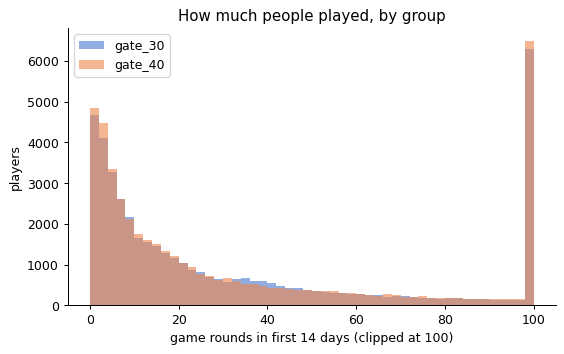

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for version, color in [('gate_30', '#4878d0'), ('gate_40', '#ee854a')]:
    rounds = df.loc[df['version'] == version, 'sum_gamerounds'].clip(upper=100)
    ax.hist(rounds, bins=range(0, 102, 2), alpha=0.6, label=version, color=color)
ax.set_xlabel('game rounds in first 14 days (clipped at 100)')
ax.set_ylabel('players')
ax.set_title('How much people played, by group')
ax.legend()
plt.show()

Clean: no missing values, no duplicate users, roughly 45k per group.

Two things worth noting. The round counts are very skewed: the median player plays 16-17 rounds, but one `gate_30` player logged 49,854 rounds in 14 days, which is either a bot or someone with a serious problem. Since retention is a yes/no flag per player, outliers like that can't drag the main metrics around, so I'm leaving them in. And the split isn't exactly even: 44,700 vs 45,489. I check whether that's within random luck in section 6.